# 03 · Características radiómicas de primer orden

Este notebook documenta la extracción de características radiómicas y revisa cuáles son redundantes, para definir con qué columnas entran los clasificadores de TB.

**Datos que se usan para decidir.** El análisis usa *train + val* (563 imágenes). Las 141 imágenes de prueba quedan reservadas para evaluar los clasificadores.

**Relación con el resto del proyecto**

```
02 (máscaras por método) ──► 03 (este notebook) ──► clasificadores de TB
```

| Sección | Contenido |
|---|---|
| 1 | Qué se extrajo y verificación de las tablas |
| 2 | Redundancia entre características |
| 3 | Columnas para los clasificadores |
| 4 | Conclusiones y siguientes pasos |

## 1 · Qué se extrajo

`src/tbseg/radiomics/extract.py` calcula las características de los píxeles de cada radiografía que quedan dentro de la máscara de un método. La radiografía y los parámetros son los mismos para todos los métodos: **solo cambia la máscara**.

```bash
python -m tbseg.radiomics.extract --method unet
python -m tbseg.radiomics.extract --method attention_unet
python -m tbseg.radiomics.extract --method medsam
```

Cada método produce un CSV en `results/radiomics/`, con una fila por imagen. La máscara incluye ambos pulmones como una sola región y se usa tal como sale del segmentador.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

from tbseg.config import RESULTS_DIR
from tbseg.radiomics.extract import PARAMS

METHODS = {"unet": "U-Net", "attention_unet": "Attention U-Net", "medsam": "MedSAM"}
ID_COLS = ["image_id", "patient_id", "source", "tb", "split"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

tables = {m: pd.read_csv(RESULTS_DIR / "radiomics" / f"montgomery_shenzhen_firstorder_{m}.csv") for m in METHODS}
FEATURES = [c for c in tables["unet"].columns if c not in ID_COLS]
params = yaml.safe_load(PARAMS.read_text())
print(yaml.safe_dump(params["setting"], sort_keys=False))

display(pd.DataFrame({
    METHODS[m]: {
        "Imágenes": len(t),
        "Características": len(FEATURES),
        "Valores faltantes": int(t[FEATURES].isna().sum().sum()),
        "Mismas filas y orden que U-Net": t[ID_COLS].equals(tables["unet"][ID_COLS]),
        "Mínimo + voxelArrayShift > 0": bool((t["Minimum"] + params["setting"]["voxelArrayShift"]).min() > 0),
    } for m, t in tables.items()
}))

# El análisis usa solo train + val
dev = {m: t[t["split"] != "test"].reset_index(drop=True) for m, t in tables.items()}
labels = dev["unet"][ID_COLS]
print("Imágenes de train + val:", len(labels))

force2D: true
label: 1
normalize: true
normalizeScale: 100
voxelArrayShift: 400
binCount: 32



,U-Net,Attention U-Net,MedSAM
Imágenes,704,704,704
Características,18,18,18
Valores faltantes,0,0,0
Mismas filas y orden que U-Net,True,True,True
Mínimo + voxelArrayShift > 0,True,True,True


Imágenes de train + val: 563


## 2 · Redundancia entre características

Se calcula la correlación de Spearman entre las características, que captura cualquier relación monótona. Las variables se ordenan por agrupamiento jerárquico para que los grupos parecidos queden juntos. Se marcan como redundantes los pares con correlación absoluta de 0,95 o más.

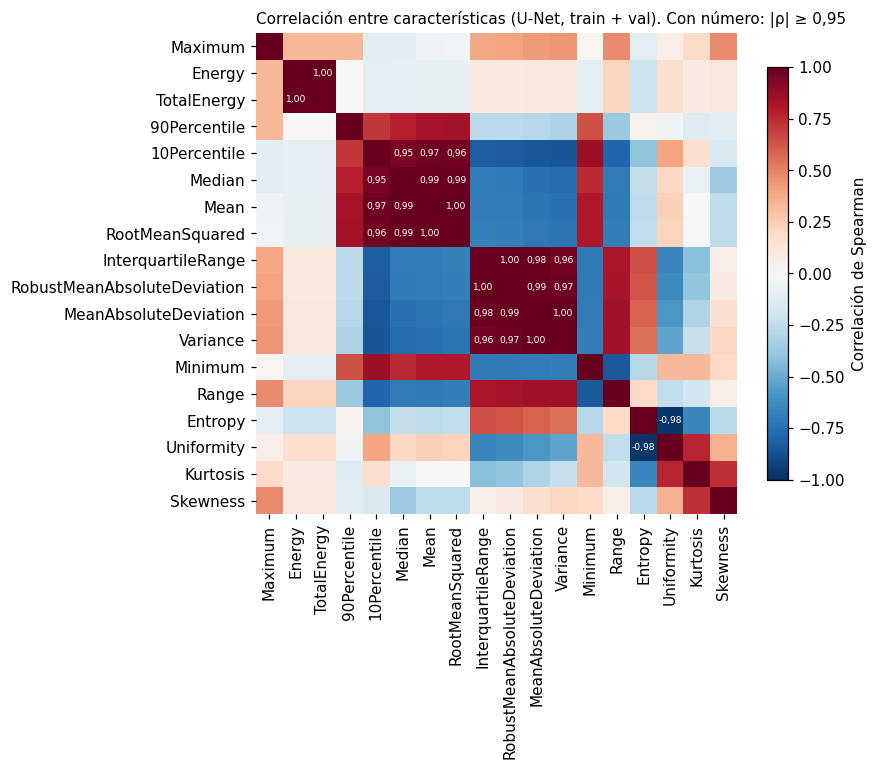

U-Net [['10Percentile', 'Mean', 'Median', 'RootMeanSquared'], ['InterquartileRange', 'MeanAbsoluteDeviation', 'RobustMeanAbsoluteDeviation', 'Variance'], ['Entropy', 'Uniformity'], ['Energy', 'TotalEnergy']]
Attention U-Net [['10Percentile', 'Mean', 'Median', 'RootMeanSquared'], ['InterquartileRange', 'MeanAbsoluteDeviation', 'RobustMeanAbsoluteDeviation', 'Variance'], ['Entropy', 'Uniformity'], ['Energy', 'TotalEnergy']]
MedSAM [['InterquartileRange', 'MeanAbsoluteDeviation', 'RobustMeanAbsoluteDeviation', 'Variance'], ['Mean', 'Median', 'RootMeanSquared'], ['Entropy', 'Uniformity'], ['Energy', 'TotalEnergy']]
Spearman con el área de la máscara (U-Net): {'Energy': 0.86, 'RootMeanSquared': -0.53, 'Mean': -0.53}
Spearman con el área de la máscara (Attention U-Net): {'Energy': 0.84, 'RootMeanSquared': -0.53, 'Mean': -0.53}
Spearman con el área de la máscara (MedSAM): {'Energy': 0.55, 'RootMeanSquared': -0.35, 'Mean': -0.36}


In [2]:
corr = dev["unet"][FEATURES].corr(method="spearman")
distance = 1 - corr.abs().values
np.fill_diagonal(distance, 0)
leaves = leaves_list(linkage(squareform(distance, checks=False), method="average"))
ordered = corr.iloc[leaves, leaves]

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(ordered, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered)), ordered.columns, rotation=90); ax.set_yticks(range(len(ordered)), ordered.index)
ax.spines[:].set_visible(False)
for i in range(len(ordered)):
    for j in range(len(ordered)):
        if i != j and abs(ordered.iat[i, j]) >= 0.95:
            ax.text(j, i, f"{ordered.iat[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=6, color="white")
fig.colorbar(image, label="Correlación de Spearman", shrink=0.8)
ax.set_title("Correlación entre características (U-Net, train + val). Con número: |ρ| ≥ 0,95", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

def groups(corr, threshold=0.95):
    pending, found = set(corr.columns), []
    while pending:
        stack, group = [pending.pop()], set()
        while stack:
            f = stack.pop(); group.add(f)
            near = set(corr.index[corr[f].abs() >= threshold]) & pending
            pending -= near; stack += near
        found.append(sorted(group))
    return sorted(found, key=len, reverse=True)

for m in METHODS:
    print(METHODS[m], [g for g in groups(dev[m][FEATURES].corr(method="spearman")) if len(g) > 1])

qc = pd.read_csv(RESULTS_DIR / "segmentation" / "mask_qc_montgomery_shenzhen.csv")
for m in METHODS:
    area = qc[qc["arch"] == m].set_index("image_id")["area_frac"].reindex(dev[m]["image_id"]).values
    print(f"Spearman con el área de la máscara ({METHODS[m]}):", dev[m][["Energy", "RootMeanSquared", "Mean"]].corrwith(pd.Series(area), method="spearman").round(2).to_dict())

**Lectura.** Los mismos cuatro grupos aparecen con las dos redes. Con MedSAM también aparecen, con una diferencia: `10Percentile` no alcanza el umbral con el grupo Posición.

| Grupo | Características | Qué mide |
|---|---|---|
| Posición | `10Percentile`, `Mean`, `Median`, `RootMeanSquared` | Qué tan clara u oscura es la región |
| Dispersión | `InterquartileRange`, `MeanAbsoluteDeviation`, `RobustMeanAbsoluteDeviation`, `Variance` | Qué tan heterogénea es |
| Complejidad | `Entropy`, `Uniformity` | Cómo se reparte el histograma |
| Magnitud | `Energy`, `TotalEnergy` | Suma de intensidades al cuadrado |

`Minimum`, `Maximum`, `Range`, `90Percentile`, `Skewness` y `Kurtosis` no alcanzan el umbral con ninguna otra. Las 18 columnas equivalen, en la práctica, a unas **10 señales distintas** (11 con MedSAM).

`Energy` y `TotalEnergy` son idénticas porque el tamaño del píxel es 1. Además, `Energy` depende sobre todo del **tamaño de la máscara** (ρ con el área: 0,86 en U-Net y 0,84 en Attention U-Net), más que de la intensidad: es la característica que más directamente recibe el efecto de la segmentación. En MedSAM la relación es menor (ρ = 0,55).

## 3 · Columnas para los clasificadores

**Propuesta:** 17 columnas, excluyendo solo `TotalEnergy`, que es idéntica a `Energy`.

Las características correlacionadas se mantienen. Con 17 variables y más de 500 imágenes de entrenamiento, el riesgo de sobreajuste es bajo, y el índice de sensibilidad necesita medir cada una por separado. Al interpretar la importancia de las variables hay que leerla por grupo, porque las correlacionadas se reparten la importancia.

In [3]:
excluded = ["TotalEnergy"]
INPUT_COLUMNS = [f for f in FEATURES if f not in excluded]
print(len(INPUT_COLUMNS), "columnas de entrada:", INPUT_COLUMNS)

17 columnas de entrada: ['10Percentile', '90Percentile', 'Energy', 'Entropy', 'InterquartileRange', 'Kurtosis', 'Maximum', 'MeanAbsoluteDeviation', 'Mean', 'Median', 'Minimum', 'Range', 'RobustMeanAbsoluteDeviation', 'RootMeanSquared', 'Skewness', 'Uniformity', 'Variance']


## 4 · Conclusiones y siguientes pasos

- **Tablas listas:** 704 imágenes y 18 características por método, sin valores faltantes y con las mismas filas.
- **Hay unas 10 señales distintas** en 18 columnas, con los mismos cuatro grupos en las dos redes. En MedSAM son 11, porque `10Percentile` sale del grupo Posición. Los clasificadores usarían 17.
- **`Energy` depende sobre todo del tamaño de la máscara** en las redes (ρ = 0,86 y 0,84), así que es la característica que más directamente recibe el efecto de la segmentación. En MedSAM la relación es menor (ρ = 0,55).

**Siguientes pasos:**

1. Entrenar los clasificadores de TB (SVM, Random Forest y red neuronal), uno por cada CSV, con la misma partición y el mismo protocolo.
2. Evaluar una sola vez en las 141 imágenes de prueba y reportar F1, AUC, sensibilidad y especificidad.